# Nav2 Point-to-Point Obstacle Test

Replay recorded execution artifacts. This notebook does not start ROS.

## Setup

Known static obstacle and ground-truth localization. No live perception or AMCL is tested.

In [1]:
from pathlib import Path
import hashlib, importlib.util, json, sys
from IPython.display import Image, Markdown, display
name = 'Nav2_test'
locations = [p for parent in [Path.cwd(), *Path.cwd().parents]
    for p in [parent, parent/name, parent/'Code/10.27_ROS_simulation'/name]]
root = next(p for p in locations if p.name == name and (p/'result').is_dir())
run = root/'result'/'run_20261027T224156_726349Z'
manifest = json.loads((run/'manifest.json').read_text())
metrics = json.loads((run/'metrics.json').read_text())
print(json.dumps(manifest['scenario'], indent=2))

{
  "case": "known_static_obstacle",
  "map_bounds_m": [
    -2.0,
    8.0,
    -4.0,
    4.0
  ],
  "resolution_m": 0.05,
  "start": [
    0.0,
    0.0,
    0.0
  ],
  "goal": [
    6.0,
    0.0,
    0.0
  ],
  "obstacle": {
    "center_m": [
      3.0,
      0.0
    ],
    "size_m": [
      1.5,
      2.0
    ],
    "height_m": 1.0
  },
  "footprint_m": [
    [
      0.36,
      0.282
    ],
    [
      0.36,
      -0.282
    ],
    [
      -0.334,
      -0.282
    ],
    [
      -0.334,
      0.282
    ]
  ],
  "footprint_padding_m": 0.07,
  "goal_xy_tolerance_m": 0.15,
  "goal_yaw_tolerance_rad": 0.15,
  "minimum_clearance_m": 0.05,
  "max_navigation_sim_s": 150.0,
  "localization": "simulator ground-truth map-to-odom correction",
  "obstacle_source": "known static map; no perception sensor or AMCL"
}


## Recorded results

| Metric | Result | Unit |
|---|---:|---|
| Final position error | 0.148902 | m |
| Final heading error | 0.144164 | rad |
| Minimum full-body clearance | 0.602915 | m |
| Physical path length | 7.469374 | m |
| Initial planned path length | 7.714858 | m |
| Navigation duration | 33.436000 | s |
| Sampled footprint overlaps | 0.000000 | samples |

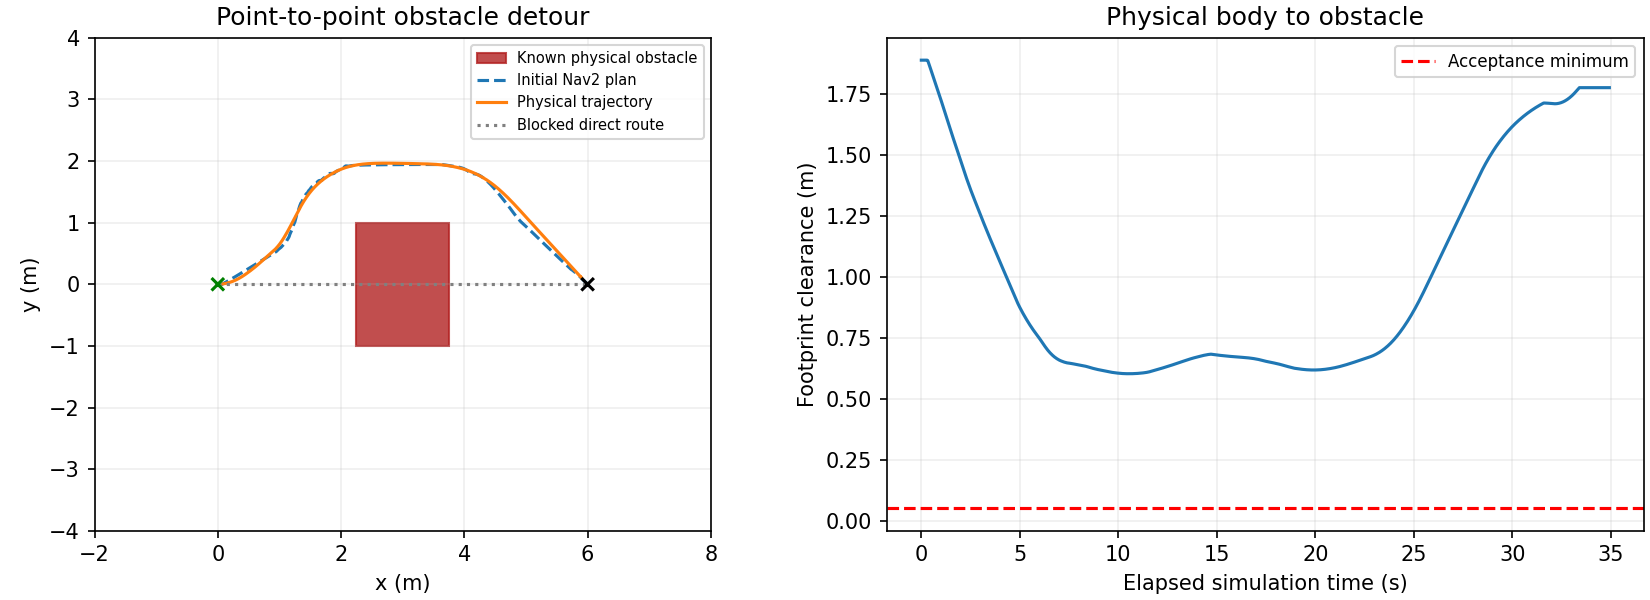

{
  "nav2_succeeded": true,
  "physical_goal_position": true,
  "physical_goal_heading": true,
  "no_sampled_body_overlap": true,
  "minimum_clearance": true,
  "body_remained_in_field": true,
  "detour_executed": true,
  "stopped_after_success": true
}


In [2]:
display(Image(filename=str(run/'navigation.png')))
print(json.dumps(metrics['checks'], indent=2))
assert metrics['status'] == 'passed' and all(metrics['checks'].values())

## Artifact and geometry verification

Verify source/data hashes, analytic geometry fixtures and recomputed footprint clearances.

In [3]:
sys.dont_write_bytecode = True
spec = importlib.util.spec_from_file_location('nav2_verification', root/'testing_code/tools/verify_results.py')
verification = importlib.util.module_from_spec(spec)
spec.loader.exec_module(verification)
verification.verify()

{
  "geometry_fixtures": 4,
  "physical_pose_samples": 1747,
  "artifact_and_source_hashes_match": true,
  "recorded_metrics_recomputed": true
}


{'geometry_fixtures': 4,
 'physical_pose_samples': 1747,
 'artifact_and_source_hashes_match': True,
 'recorded_metrics_recomputed': True}

## rosbag2 recording

The primary ROS recording is [rosbag/](result/run_20261027T224156_726349Z/rosbag), stored as MCAP with `metadata.yaml`. It contains **34961 messages across 21 topics**. Recording timestamps use simulation time. The recorder starts before the goal is sent and flushes before simulation shutdown.

| Recorded topic | Messages |
|---|---:|
| `/clock` | 18868 |
| `/cmd_vel` | 666 |
| `/global_costmap/costmap` | 63 |
| `/global_costmap/published_footprint` | 380 |
| `/local_costmap/costmap` | 61 |
| `/local_costmap/published_footprint` | 380 |
| `/lookahead_point` | 665 |
| `/map` | 1 |
| `/navigate_to_pose/_action/feedback` | 1679 |
| `/navigate_to_pose/_action/status` | 2 |
| `/odom` | 1885 |
| `/plan` | 30 |
| `/received_global_plan` | 87 |
| `/robot_description` | 1 |
| `/simulation/cmd_vel` | 760 |
| `/simulation/ground_truth/odom` | 1887 |
| `/simulation/track_odom` | 1887 |
| `/simulation/track_tf` | 1886 |
| `/test/navigation_goal` | 1 |
| `/tf` | 3771 |
| `/tf_static` | 1 |

Readback status: **passed**. The bag contains the map, static and dynamic TF, goal, action status and physical motion throughout navigation. The bag/analysis pose match fraction is 1.000; minimum footprint clearance independently recomputed from bag poses is 0.602915 m. CSV and JSON remain analysis products, checked against the authoritative ROS recording.

Actual ROS playback was also verified at 5× speed on isolated domain 73, without replaying velocity-command topics: **passed**. See [bag info](result/run_20261027T224156_726349Z/rosbag_info.txt), [readback checks](result/run_20261027T224156_726349Z/rosbag_summary.json), and [playback checks](result/run_20261027T224156_726349Z/rosbag_replay_verification.json).

To inspect or replay this run inside the container:

```bash
source /opt/ros/jazzy/setup.bash
export ROS_DOMAIN_ID=73
bag=/workspace/Code/10.27_ROS_simulation/Nav2_test/result/run_20261027T224156_726349Z/rosbag
ros2 bag info "$bag"
ros2 bag play "$bag" --clock --topics /tf /tf_static /map /odom /plan /robot_description /simulation/ground_truth/odom /test/navigation_goal /global_costmap/costmap /local_costmap/costmap
```

Use the same domain and `use_sim_time:=true` for RViz; set its fixed frame to `map`. This replays ROS data for inspection; it does not rerun Gazebo physics or reissue the navigation action. The visualization replay excludes velocity commands. Transient-local QoS overrides preserve latched map, static TF and model data; see [rosbag_qos.yaml](testing_code/src/well_e_nav2_test/config/rosbag_qos.yaml). Reference: [ROS 2 rosbag2 recording and QoS](https://github.com/ros2/rosbag2/blob/rolling/README.md).


In [4]:
recording = json.loads((run/'rosbag_summary.json').read_text())
replay = json.loads((run/'rosbag_replay_verification.json').read_text())
assert recording['status'] == 'passed' and all(recording['checks'].values())
assert replay['status'] == 'passed'
assert replay['ros_domain_id'] == 73 and not replay['command_topics_replayed']
assert (run/'rosbag/metadata.yaml').is_file()
assert list((run/'rosbag').glob('*.mcap'))
print('rosbag2 MCAP record, readback and isolated playback verified.')

rosbag2 MCAP record, readback and isolated playback verified.


## Embedded replay video

The [Notebook](test_report.ipynb) embeds a playable [MP4](result/run_20261027T224156_726349Z/replay/rosbag_replay.mp4) generated directly from the physical-pose messages in the MCAP recording. Duration: 35.08 s, at 1× simulation-time speed and 12 fps.

This is a top-down recorded-data visualization of the robot footprint, heading and route, **not camera footage or a Gazebo screen recording**. The bag contains no recorded image topics. Frames use the nearest recorded pose without interpolating positions. The scenario comes from the saved run configuration.

Provenance and full-video decode verification: [video_metadata.json](result/run_20261027T224156_726349Z/replay/video_metadata.json). Decoded bag poses: [bag_poses.csv](result/run_20261027T224156_726349Z/replay/bag_poses.csv). Creating the video does not rerun navigation or modify the original bag.


In [5]:
from IPython.display import Video
video = run/'replay/rosbag_replay.mp4'
video_metadata = json.loads((run/'replay/video_metadata.json').read_text())
assert video_metadata['status'] == 'verified'
assert video_metadata['kind'] == 'rosbag_pose_visualization'
assert not video_metadata['camera_footage']
assert hashlib.sha256(video.read_bytes()).hexdigest() == video_metadata['video_sha256']
assert hashlib.sha256((run/'replay/bag_poses.csv').read_bytes()).hexdigest() == video_metadata['pose_csv_sha256']
assert all(hashlib.sha256((run/'rosbag'/name).read_bytes()).hexdigest() == digest
           for name, digest in video_metadata['bag_sha256'].items())
display(Video(filename=str(video), embed=True, width=900,
              html_attributes='controls preload="metadata"'))

## Interpretation

Nav2 executed a detour around a known obstacle and reached the goal with the simulated Bunker Mini. Ground-truth localization isolates planning/control from localization error. This is not evidence of detecting unmapped obstacles or navigating on hardware. See the [README](README.md) for coverage and commands.